# Lab 4 — Notebook 1: Object Detection · African-wildlife

**Group members:** *Elias Hawkins & Davin Matias*

**Task:** Detect and classify animals with bounding boxes  
**Dataset:** `african-wildlife.yaml`  
**Starting weights:** `yolo26n.pt`

**Constraints (from the lab manual):**
- Ultralytics YOLO on Google Colab with a T4 GPU
- Nano (`n`) model only
- `imgsz=640`, `batch=16`, `seed=0`
- Epochs: **20–50** (you choose within this range)
- Save training runs to Google Drive
- Predictions and reflection answers must be your own writing (no AI)

Work top to bottom. Write each **Prediction** *before* you run the code that follows it.


---
## Step 0: Setup and data check

Install Ultralytics, mount Drive, load the dataset, and verify it matches the lab tables.


### Install and imports


In [1]:
# Runtime → Change runtime type → T4 GPU (recommended)
!pip -q install ultralytics


In [2]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ultralytics
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

print("Ultralytics:", ultralytics.__version__)
ultralytics.checks()


Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.6/112.6 GB disk)


### Mount Google Drive (so disconnects don't erase training runs)


In [3]:
from google.colab import drive

drive.mount("/content/drive")

# Change this if you want a different save location on Drive
DRIVE_ROOT = Path("/content/drive/MyDrive/IT480_Lab4")
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
print("Saving runs under:", DRIVE_ROOT)


Mounted at /content/drive
Saving runs under: /content/drive/MyDrive/IT480_Lab4


### Config for this notebook

Expected dataset (from the lab manual):

| Property | Value |
| --- | --- |
| Classes | 4: buffalo, elephant, rhino, zebra |
| Images | 1,504 total: 1,052 train / 225 val / 227 test |
| Label format | `class x_center y_center width height` |


In [4]:
# ---- Notebook config ----
TASK = "detect"
DATA_YAML = "african-wildlife.yaml"
WEIGHTS = "yolo26n.pt"
IMGSZ = 640
BATCH = 16
SEED = 0

# YOU choose epochs within 20–50 (fill Prediction 2 before changing this)
EPOCHS = 30  # TODO: set your chosen epoch count
PATIENCE = 5

PROJECT_DIR = DRIVE_ROOT / "detection"
RUN_NAME = "detect_run"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Task={TASK} | data={DATA_YAML} | weights={WEIGHTS}")
print(f"epochs={EPOCHS} | imgsz={IMGSZ} | batch={BATCH} | seed={SEED}")
print(f"project={PROJECT_DIR} | name={RUN_NAME}")


Task=detect | data=african-wildlife.yaml | weights=yolo26n.pt
epochs=30 | imgsz=640 | batch=16 | seed=0
project=/content/drive/MyDrive/IT480_Lab4/detection | name=detect_run


### Download / locate the dataset and print class names + split sizes


In [5]:
# check_det_dataset downloads the zip on first use and returns parsed YAML fields
data_info = check_det_dataset(DATA_YAML)

DATA_ROOT = Path(data_info["path"])
NAMES = data_info["names"]
if isinstance(NAMES, list):
    NAMES = {i: n for i, n in enumerate(NAMES)}

print("Dataset root:", DATA_ROOT)
print("Class names:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")
print("Number of classes:", len(NAMES))


def list_images(split: str):
    split_rel = data_info.get(split)
    if not split_rel:
        return []
    # YAML values are relative to DATA_ROOT (e.g. "images/train")
    split_dir = Path(split_rel)
    if not split_dir.is_absolute():
        split_dir = DATA_ROOT / split_dir
    if not split_dir.exists():
        return []
    return sorted(
        p for p in split_dir.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )

train_imgs = list_images("train")
val_imgs = list_images("val")
test_imgs = list_images("test")

print("\nImage counts:")
print(f"  train: {len(train_imgs)}")
print(f"  val:   {len(val_imgs)}")
print(f"  test:  {len(test_imgs)}")
print(f"  total: {len(train_imgs) + len(val_imgs) + len(test_imgs)}")

# Soft checks against the lab tables (edit EXPECTED if the manual differs)
EXPECTED = {'train': 1052, 'val': 225, 'test': 227}
for split, n in EXPECTED.items():
    got = {"train": len(train_imgs), "val": len(val_imgs), "test": len(test_imgs)}[split]
    status = "OK" if got == n else f"MISMATCH (expected {n})"
    print(f"  check {split}: {got} -> {status}")



WARNING ⚠️ Dataset 'african-wildlife.yaml' images not found, missing path '/content/datasets/african-wildlife/images/val'
Unzipping /content/datasets/african-wildlife.zip to /content/datasets/african-wildlife...: 100% ━━━━━━━━━━━━ 3018/3018 2.9Kfiles/s 1.0s
Dataset download success ✅ (3.0s), saved to /content/datasets

Dataset root: /content/datasets/african-wildlife
Class names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra
Number of classes: 4

Image counts:
  train: 1052
  val:   225
  test:  227
  total: 1504
  check train: 1052 -> OK
  check val: 225 -> OK
  check test: 227 -> OK


### Display ≥3 images with ground-truth labels


In [6]:
import cv2

# Distinct BGR colors for overlays
colors = [
    (255, 56, 56), (255, 157, 151), (255, 112, 31), (255, 178, 29),
    (207, 210, 49), (72, 249, 10), (146, 204, 23), (61, 219, 134),
    (26, 147, 52), (0, 212, 187), (44, 153, 168), (0, 194, 255),
    (52, 69, 147), (70, 70, 70), (153, 153, 153), (255, 255, 255),
]


def show_ground_truth(img_paths, names, n=3, seed=0):
    """Display n images with ground-truth labels drawn on them."""
    rng = random.Random(seed)
    chosen = rng.sample(list(img_paths), k=min(n, len(img_paths)))

    fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5))
    if len(chosen) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, chosen):
        img_path = Path(img_path)
        # labels/ mirrors images/ (train|val|test)
        label_path = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        true_labels = []

        # Detection labels: class xc yc w h  (normalized)
        if label_path.exists():
            for line in label_path.read_text().strip().splitlines():
                parts = line.split()
                if len(parts) < 5:
                    continue
                cls_id = int(float(parts[0]))
                true_labels.append(names.get(cls_id, str(cls_id)))
                xc, yc, bw, bh = map(float, parts[1:5])
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
                color = colors[cls_id % len(colors)]
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                cv2.putText(
                    img,
                    names.get(cls_id, str(cls_id)),
                    (x1, max(15, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    color,
                    2,
                    cv2.LINE_AA,
                )

        # Title = true class name(s); filename kept on a second line
        title = ", ".join(true_labels) if true_labels else "(no labels)"

        ax.imshow(img)
        ax.set_title(f"{title}\n{img_path.name}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    return chosen

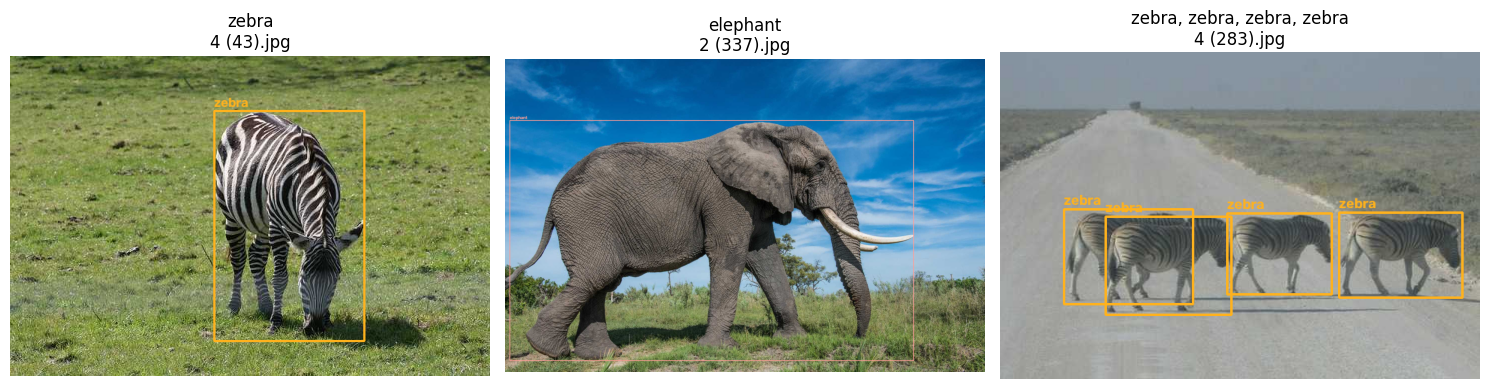

Shown: ['4 (43).jpg', '2 (337).jpg', '4 (283).jpg']


In [7]:
gt_examples = show_ground_truth(val_imgs, NAMES, n=3, seed=0)
print("Shown:", [Path(p).name for p in gt_examples])


### Checkpoint 1: The data is what you expect

**Write your answer below (your own words):**
- Do the printed class names and split counts match the lab tables?
- Do the ground-truth overlays line up with the objects?

**Both the printed class names and split counts match the lab tables. The ground-truth overlays also line up with the objects.**


---
## Step 1: Baseline (pretrained model, no training)

Run the COCO-pretrained model **as-is** on five validation images.


### Prediction 1

What do you expect the COCO-pretrained model to get right and wrong on this dataset? Why?

**We expect the model to always be able to identify a Zebra because this class is pretty distinct from the other classes because it has stripes and a unique shape compared to the other classes. We exepct that the pretrained model could confuse a Rhino with a Elephnat because they're similar colors and shapes. This could also apply to differentiating a Rhino from a Buffalo.**


In [8]:
def show_predictions(model, img_paths, title_prefix="pred", true_names=None):
    """Run model on images and display annotated results with matplotlib (Colab-safe).

    Titles show true labels (from YOLO label files, when available) and predicted labels.
    `true_names` should be the dataset class-name dict (e.g. NAMES). If omitted, true
    labels are skipped (useful for real-world URLs with no label files).
    """
    results = model.predict(source=[str(p) for p in img_paths], imgsz=640, verbose=False)

    fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 5))
    if len(results) == 1:
        axes = [axes]

    for ax, r, p in zip(axes, results, img_paths):
        annotated = r.plot()  # BGR ndarray
        ax.imshow(annotated[:, :, ::-1])

        # Predicted class names from this model
        if r.boxes is not None and len(r.boxes):
            pred_ids = [int(c) for c in r.boxes.cls.cpu().tolist()]
            pred_labels = [model.names[i] for i in pred_ids]
            pred_str = ", ".join(pred_labels) if pred_labels else "(none)"
        else:
            pred_str = "(none)"

        # True class names from matching label file (dataset images only)
        true_str = None
        if true_names is not None:
            img_path = Path(p)
            label_path = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
            true_labels = []
            if label_path.exists():
                for line in label_path.read_text().strip().splitlines():
                    parts = line.split()
                    if len(parts) < 5:
                        continue
                    cls_id = int(float(parts[0]))
                    true_labels.append(true_names.get(cls_id, str(cls_id)))
            true_str = ", ".join(true_labels) if true_labels else "(none)"

        if true_str is not None:
            ax.set_title(f"True: {true_str}\nPred: {pred_str}")
        else:
            ax.set_title(f"{title_prefix}\nPred: {pred_str}\n{Path(p).name}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    return results

In [9]:
baseline = YOLO(WEIGHTS)

print("Pretrained model class names:")
print(baseline.names)
print("Number of pretrained classes:", len(baseline.names))


Pretrained model class names:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard',

In [10]:
print("\nDataset class names for comparison:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")



Dataset class names for comparison:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra


Baseline images: ['4 (43).jpg', '2 (337).jpg', '4 (283).jpg', '2 (55).jpg', '1 (15).jpg']


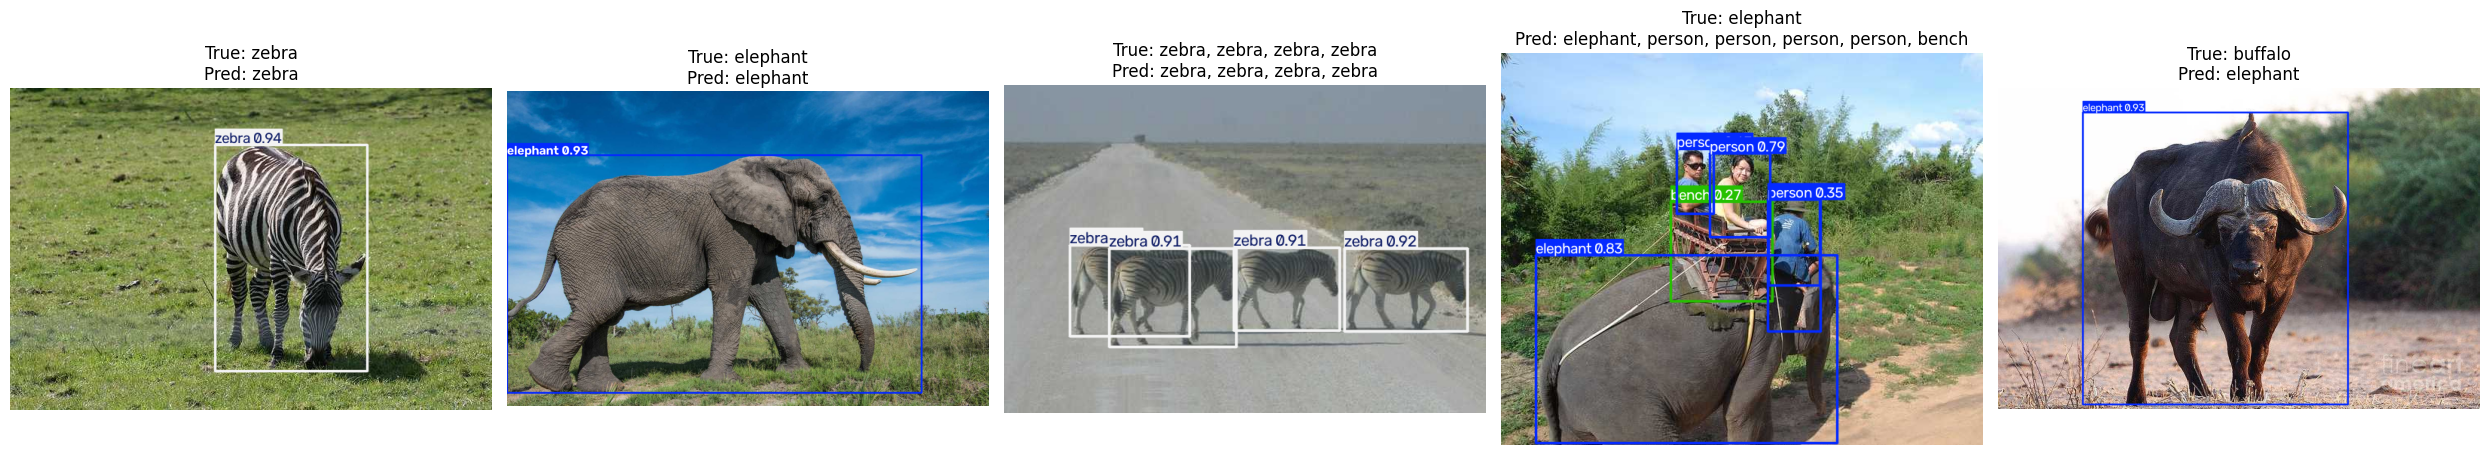

In [11]:
# Five validation images (fixed seed so your write-up is reproducible)
rng = random.Random(0)
baseline_imgs = rng.sample(val_imgs, k=min(5, len(val_imgs)))
print("Baseline images:", [Path(p).name for p in baseline_imgs])

baseline_results = show_predictions(
    baseline,
    baseline_imgs,
    title_prefix="baseline",
    true_names=NAMES,  # dataset labels for "True:"; model.names used for "Pred:"
)

### Checkpoint 2: Why the baseline fails

**Write your answer below (your own words):**
- Compare the pretrained model's class names (or keypoint count) with the dataset's. What went wrong in your five images?

- **The only thing that went wrong is that the model predicted an image of a buffalo to be an elephant.**

- Explain why a baseline mAP computed on this dataset with the pretrained model would be meaningless. Hint: what does class 0 mean to each one?

- **The baseline mAP is predicted as correct if the box overlaps enough and the predicted label matches the actual label. Both models use integers to map classes to labels but the models map the integers to different labels. For example, class 0 in this dataset maps to a buffalo, whereas class 0 maps to a person in the COCO-pretrained model.**

**Task-specific:** Which animals did the baseline handle, and what did it call the others?

**The baseline was able to handle zebras correctly. It also predicted elephants correctly, but when presented with images of buffalos, it mis-predicted and classified buffalos as elephants.**


---
## Step 2: Fine-tuning (transfer learning)

Start from the pretrained weights and train on this dataset with the required settings.


### Prediction 2 *(write BEFORE training)*

What mAP50 do you expect after fine-tuning? How many epochs do you think you'll need (within 20–50)?

**We predict the mAP50 to be 0.90 after fine-tuning. We think that it'll need around 30 epochs.**

Then set `EPOCHS` in the config cell above to match your choice, and re-run that cell before training.


In [12]:
# Fine-tune. Watch the training log for the "Transferred X/Y items" line.
# Early stopping: training ends early if val metrics stall for PATIENCE epochs.
ft_model = YOLO(WEIGHTS)

train_results = ft_model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    patience=PATIENCE,  # early stopping
    imgsz=IMGSZ,
    batch=BATCH,
    seed=SEED,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,  # avoid detect_run2 / detect_run3 confusion
)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=detect_run, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

### Locate the run directory and display training curves


Run directory: /content/drive/MyDrive/IT480_Lab4/detection/detect_run
Weights: [PosixPath('/content/drive/MyDrive/IT480_Lab4/detection/detect_run/weights/last.pt'), PosixPath('/content/drive/MyDrive/IT480_Lab4/detection/detect_run/weights/best.pt')]


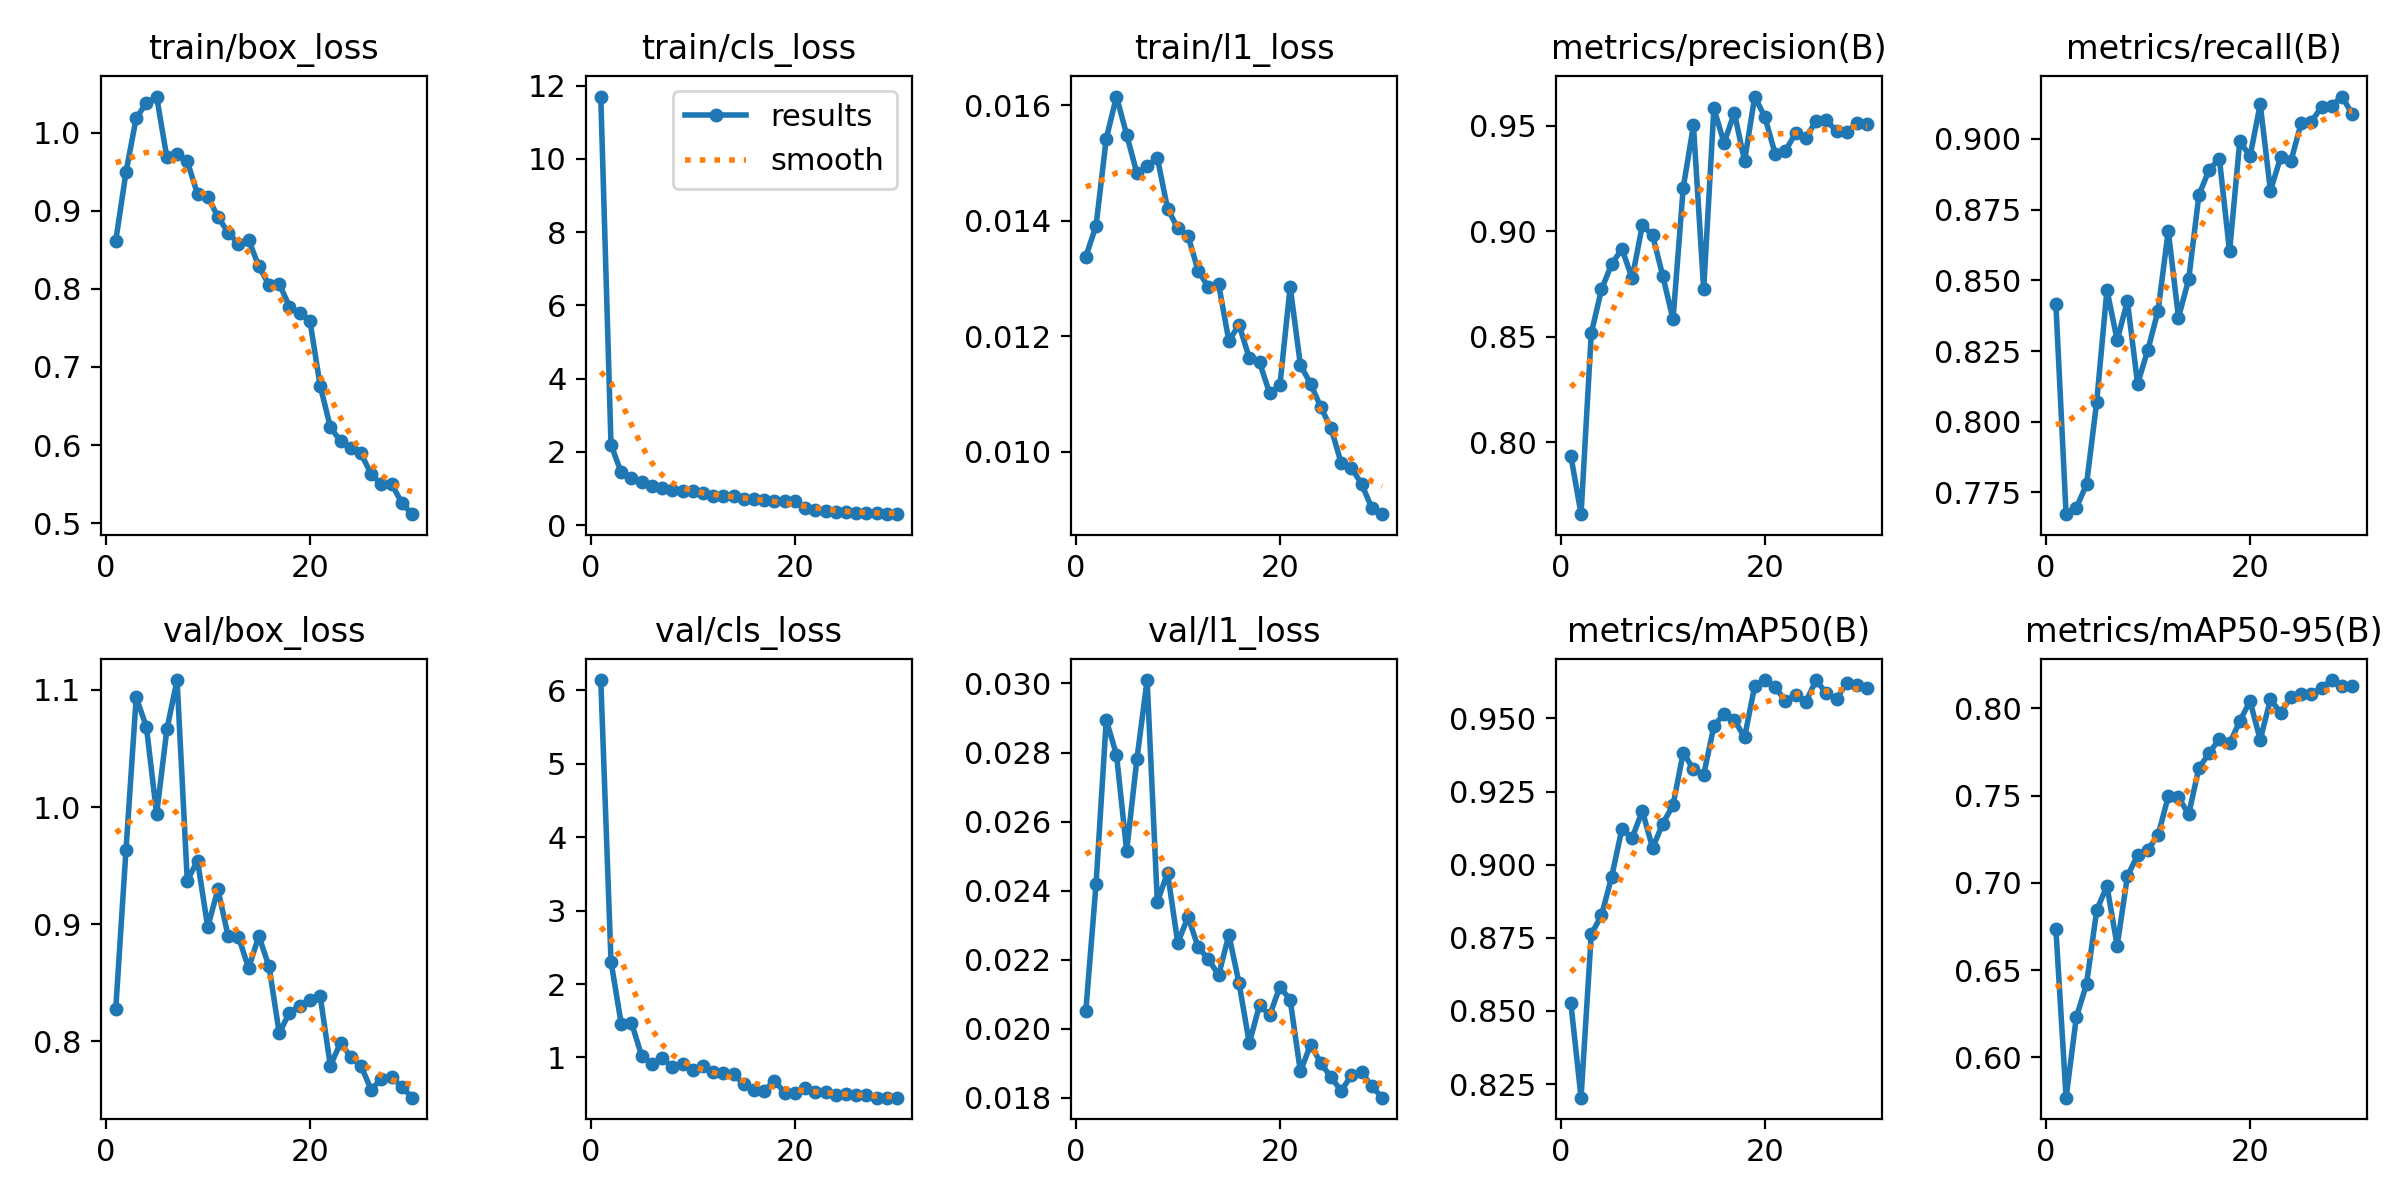

,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
25,26,560.527,0.56255,0.32659,0.00980,0.95263,0.90611,0.95861,0.80840,0.75866,0.49563,0.01820,0.000219,0.000219,0.000219
26,27,579.781,0.54975,0.32582,0.00972,0.94745,0.91133,0.95660,0.81180,0.76794,0.48366,0.01865,0.000178,0.000178,0.000178
27,28,601.531,0.55020,0.32830,0.00944,0.94712,0.91172,0.96207,0.81629,0.76917,0.45306,0.01873,0.000136,0.000136,0.000136
28,29,622.674,0.52563,0.31493,0.00902,0.95124,0.91501,0.96134,0.81299,0.76125,0.45330,0.01833,0.000095,0.000095,0.000095
29,30,641.308,0.51145,0.29909,0.00892,0.95071,0.90887,0.96044,0.81264,0.75187,0.45280,0.01800,0.000054,0.000054,0.000054


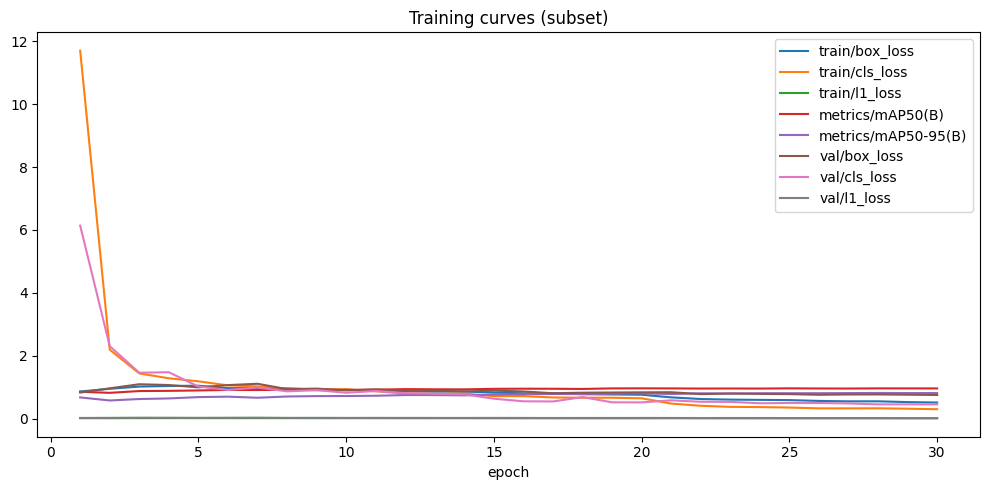

In [13]:
# Ultralytics writes under project/name (and may append a suffix if exist_ok=False)
RUN_DIR = Path(ft_model.trainer.save_dir)
print("Run directory:", RUN_DIR)
print("Weights:", list((RUN_DIR / "weights").glob("*.pt")))

results_png = RUN_DIR / "results.png"
results_csv = RUN_DIR / "results.csv"

if results_png.exists():
    display(IPImage(filename=str(results_png)))
else:
    print("results.png not found yet")

if results_csv.exists():
    curves = pd.read_csv(results_csv)
    curves.columns = [c.strip() for c in curves.columns]
    display(curves.tail())

    # Plot a few key columns if present
    plot_cols = [c for c in curves.columns if any(k in c for k in ("map", "mAP", "loss", "precision", "recall"))]
    # Prefer a compact set
    preferred = [c for c in curves.columns if c in {
        "epoch",
        "metrics/mAP50(B)", "metrics/mAP50-95(B)",
        "metrics/mAP50(M)", "metrics/mAP50-95(M)",
        "metrics/mAP50(P)", "metrics/mAP50-95(P)",
        "train/box_loss", "val/box_loss",
        "train/cls_loss", "val/cls_loss",
        "train/dfl_loss", "val/dfl_loss",
        "train/pose_loss", "val/pose_loss",
        "train/kobj_loss", "val/kobj_loss",
        "train/seg_loss", "val/seg_loss",
    } or "mAP50" in c or c.endswith("_loss")]

    cols_to_plot = [c for c in preferred if c != "epoch" and c in curves.columns]
    if cols_to_plot:
        ax = curves.plot(x="epoch" if "epoch" in curves.columns else None, y=cols_to_plot[:8], figsize=(10, 5))
        ax.set_title("Training curves (subset)")
        plt.tight_layout()
        plt.show()


In [17]:
# Confirm the fine-tuned model now uses the dataset class names
best_path = RUN_DIR / "weights" / "best.pt"
assert best_path.exists(), f"Missing best.pt at {best_path}"

ft_best = YOLO(str(best_path))
print("Fine-tuned model class names:")
for i, name in ft_best.names.items():
    print(f"  {i}: {name}")

print("\nDataset class names:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")

print("\nNames match:", dict(ft_best.names) == dict(NAMES))

Fine-tuned model class names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra

Dataset class names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra

Names match: True


### Checkpoint 3: Transfer learning did what you intended

**Write your answer below (your own words):**
- Find the line `Transferred X/Y items` in the training log. Which parts of the network could not be transferred from the pretrained model, and why?

**The line above says "Transferred 708/708 items from pretrained weights". All parts of the network were able to be transferred from the pretrained model.**

- Do the fine-tuned model's class names now match the dataset?

**The fine-tuned model's class names now match the dataset as seen by the output above.**

- Justify your epoch choice using the training curves. Enough? Still improving? Any overfitting in validation losses?

**The epoch choice was enough because the model continued improving (all losses continously decreased) across all 30 epochs. We could probably even increase the epoch value and monitor decrease of loss until it stops decreasing or starts increasing to find the perfect value.**

**Task-specific:** Your log may say every item transferred. Look up Ultralytics' `cls_remap` training setting. Which of your four classes got a head start from COCO's class weights, and which started from scratch?

---
## Step 3: Evaluation

Evaluate **`best.pt`** (not `last.pt`) on the **test** split.


In [18]:
# Honest evaluation on the held-out split specified by the lab
metrics = ft_best.val(
    data=DATA_YAML,
    split="test",
    imgsz=IMGSZ,
    plots=True,
)

# print(metrics)

print("\n--- Box metrics ---")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print("Per-class AP50:")
for i, ap in enumerate(metrics.box.ap50):
    print(f"  {NAMES[i]}: {ap:.4f}")


Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 956.3±350.3 MB/s, size: 38.8 KB)
val: Scanning /content/datasets/african-wildlife/labels/test.cache... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 25.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.6it/s 3.3s
                   all        227        375       0.96      0.937      0.972      0.847
               buffalo         49         66      0.953      0.918      0.944       0.87
              elephant         58         99      0.969      0.949       0.98      0.797
                 rhino         55         75      0.986      0.956      0.991       0.92
                 zebra         66        135      0.932      0.926      0.974        0.8
Speed: 1.7ms preprocess, 4.1m

### Results table

| Model | Epochs | Split | mAP50 | mAP50-95 |
| --- | --- | --- | --- | --- |
| Baseline (pretrained) | — | — | Not meaningful (see Checkpoint 2) | — |
| Fine-tuned (`best.pt`) | 30 | `test` | 0.972 | 0.847 |


Fill in the blanks from the `val` output above.


### Checkpoint 4: Reading the metrics

**Write your answer below (your own words):**
- Report mAP50 and mAP50-95 (and fill the table).

**The mAP50 is 0.972 and the mAP50-95 is 0.847.**

- In one sentence, what does your mAP50 mean in plain language?

**Our mAP50 means that the fine-tuned model has an extremely high accuracy.**

- Why is the test score a fairer measure than the validation score shown during training?

**During training, YOLO checks the validation set across all epochs and keeps the weights that look the best. On the other hand, the test set is not used to update weights, we evaluate it once at the end which is why it is a better metric to use to evaluate performance.**

**Task-specific:** Which animal has the lowest AP? Why might it be the hardest?

**Buffalo has the lowest AP. This might be the hardest because it has the lowest instances in the test set. It only has 66 wheras zebras have 135.**


---
## Step 4: Real-world test

Use **three** images (or one clip ≤15s) from a free-license site (Pexels, Pixabay, Unsplash). Not from the dataset.


### Prediction 3 *(write BEFORE running inference)*

Which of your real-world images will be hardest for the model? Why?

**We think that images of animals that look like buffalos (like an American Bison) will be hardest for the model. This could be hard for the model because it will confuse similarly looking animals and our AP above for buffalo was the lowest across all classes.**


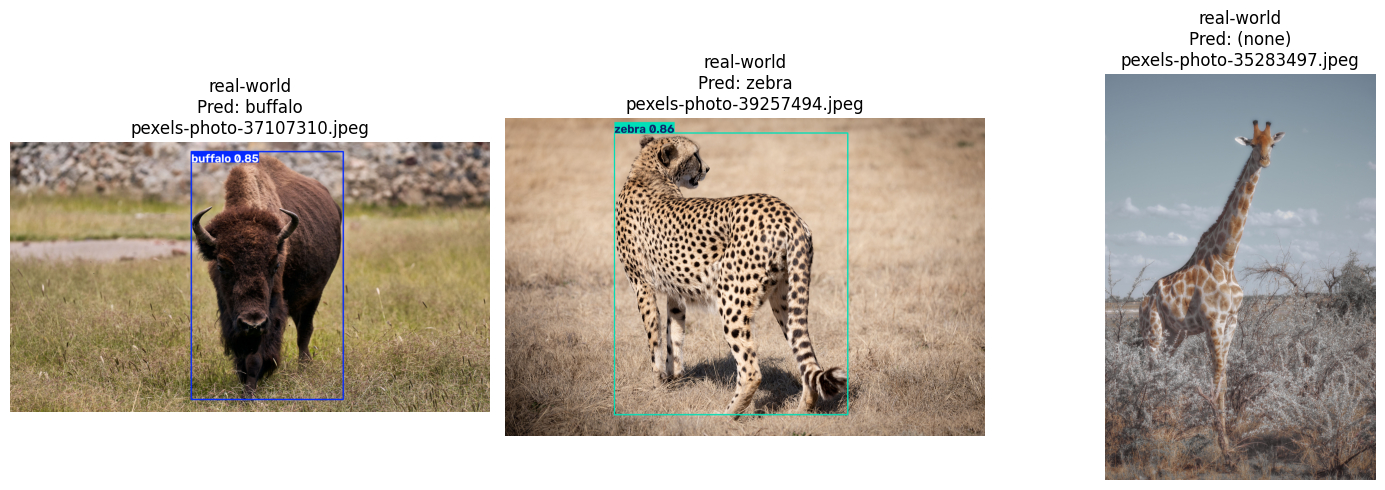

In [19]:
# Replace these with THREE free-license image URLs you chose (Pexels / Pixabay / Unsplash).
# Keep Prediction 3 written before you run this cell.
REAL_WORLD_SOURCES = [
    "https://images.pexels.com/photos/37107310/pexels-photo-37107310.jpeg",   # American Bison
    "https://images.pexels.com/photos/39257494/pexels-photo-39257494.jpeg",   # Cheetah
    "https://images.pexels.com/photos/35283497/pexels-photo-35283497.jpeg",   # Giraffe
]

assert len(REAL_WORLD_SOURCES) >= 3, "Add at least 3 image URLs before running."

rw_results = show_predictions(ft_best, REAL_WORLD_SOURCES, title_prefix="real-world")


### Checkpoint 5: Sources and results

**Write your answer below (your own words):**
- List each image's source URL and license.
- Was Prediction 3 right? What is different about real-world images vs. the dataset?

| # | Source URL | License | Notes |
| --- | --- | --- | --- |
| 1 | https://images.pexels.com/photos/37107310/pexels-photo-37107310.jpeg | Free | Picture of American Bison |
| 2 | https://images.pexels.com/photos/39257494/pexels-photo-39257494.jpeg | Free | Picture of Cheetah |
| 3 | https://images.pexels.com/photos/35283497/pexels-photo-35283497.jpeg | Free | Picture of Giraffe |

**Prediction three was correct, the model incorrectly predicted a picture of an American Bison as a buffalo. The dataset only contains four classes which is why the model only chose from buffalo, zebra, elephant or rhino.**


---
## Step 5: Failure analysis

Find one honest failure of the fine-tuned model (missed object, wrong class, bad outline, or misplaced keypoints).


Scanned 227 images; found 30 mismatches
[0] 4 (105).jpg: true=['zebra', 'zebra'] | pred=['zebra', 'zebra', 'zebra', 'zebra', 'zebra'] | confs=[0.932, 0.916, 0.684, 0.656, 0.313] | count_diff=3
[1] 4 (200).jpg: true=['zebra'] | pred=['zebra', 'zebra', 'zebra', 'zebra'] | confs=[0.924, 0.696, 0.574, 0.417] | count_diff=3
[2] 4 (294).jpg: true=['zebra', 'zebra', 'zebra', 'zebra', 'zebra', 'zebra'] | pred=['zebra', 'zebra', 'zebra', 'zebra', 'zebra', 'zebra', 'zebra', 'zebra', 'zebra'] | confs=[0.881, 0.87, 0.844, 0.836, 0.727, 0.53, 0.503, 0.419, 0.302] | count_diff=3
[3] 2 (115).jpg: true=['elephant'] | pred=['elephant', 'elephant', 'elephant'] | confs=[0.938, 0.485, 0.256] | count_diff=2
[4] 2 (290).jpg: true=['elephant', 'zebra', 'zebra'] | pred=['zebra', 'zebra', 'elephant', 'zebra', 'zebra'] | confs=[0.931, 0.911, 0.767, 0.552, 0.262] | count_diff=2
[5] 4 (257).jpg: true=['zebra', 'zebra'] | pred=['zebra', 'zebra', 'zebra', 'zebra'] | confs=[0.867, 0.665, 0.457, 0.273] | count_diff=2

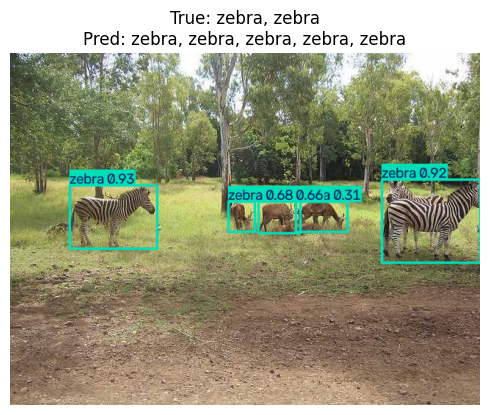

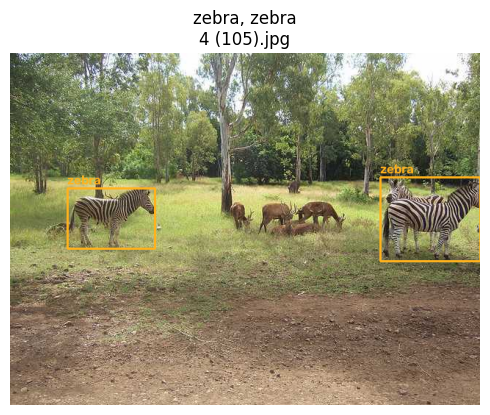

In [21]:
# Find a real failure by comparing predictions to ground-truth labels.
# Re-run this cell after training + loading ft_best.

from collections import Counter

def gt_class_names(img_path, names):
    label_path = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
    labels = []
    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            parts = line.split()
            if len(parts) >= 5:
                cls_id = int(float(parts[0]))
                labels.append(names.get(cls_id, str(cls_id)))
    return labels


candidate_pool = test_imgs if test_imgs else val_imgs
fail_candidates = []

for p in candidate_pool:
    r = ft_best.predict(source=str(p), imgsz=IMGSZ, verbose=False)[0]
    true_labels = gt_class_names(p, NAMES)

    if r.boxes is not None and len(r.boxes):
        pred_ids = [int(c) for c in r.boxes.cls.cpu().tolist()]
        pred_labels = [ft_best.names[i] for i in pred_ids]
        confs = [round(float(c), 3) for c in r.boxes.conf.cpu().tolist()]
    else:
        pred_labels, confs = [], []

    count_mismatch = abs(len(pred_labels) - len(true_labels))
    label_mismatch = Counter(pred_labels) != Counter(true_labels)
    if count_mismatch > 0 or label_mismatch:
        fail_candidates.append(
            {
                "path": p,
                "true": true_labels,
                "pred": pred_labels,
                "confs": confs,
                "count_mismatch": count_mismatch,
            }
        )

print(f"Scanned {len(candidate_pool)} images; found {len(fail_candidates)} mismatches")
fail_candidates.sort(key=lambda d: -d["count_mismatch"])

for i, d in enumerate(fail_candidates[:10]):
    print(
        f"[{i}] {Path(d['path']).name}: "
        f"true={d['true']} | pred={d['pred']} | confs={d['confs']} | "
        f"count_diff={d['count_mismatch']}"
    )

assert fail_candidates, "No mismatches found — inspect images manually or lower conf."

# Change this index after looking at the list above
FAIL_INDEX = 0
fail = fail_candidates[FAIL_INDEX]
fail_img = fail["path"]

print("\nShowing failure case:", fail_img)
print("True:", fail["true"])
print("Pred:", fail["pred"])

_ = show_predictions(ft_best, [fail_img], title_prefix="failure", true_names=NAMES)
_ = show_ground_truth([fail_img], NAMES, n=1, seed=0)

### Checkpoint 6: One honest failure

**Write your answer below (your own words):**
- Show/describe the failure case.

**The failure case is that the model falsely identified other animals in the picture as zebras.**

- Name the likely cause: small object, occlusion, unusual angle, lighting, out-of-distribution, or other.

**The model assumed that animals standing very close to each other are of the same species. Additionally, the animals are small and it is hard to tell what they are.**

- In 2–3 sentences, explain why that cause produced the failure.

**Because the model can only output buffalo, elephant, rhino, or zebra, an animal outside that label set still gets forced into one of those classes. The distant antelope/deer share a four-legged grassland context with zebras, so the model assigned them "zebra" instead of ignoring them. Their smaller size and lower detail made the mistake easier, which shows up as the extra mid-confidence zebra boxes in the prediction plot.**

---
## Reflection questions

Answer in your own words, using your results as evidence. **Do not use AI to write these.**


### Notebooks 1 and 2 — answer both

1. Compare your predictions with what actually happened. Which surprised you, and what did you learn from the surprise?

**Our predictions were partly correct; however, we were surprised that the model incorrectly identified zebras even though the mAP50 score for zebras was 0.974.**

2. In this task, what did transfer learning give you that the baseline couldn't?

**The baseline had just learned everyday objects, whereas transfer learning allowed us to train on specific african wildlife images of the classes we were predicting.**


---
## AI log

Record important AI interactions (aim for 3–5 entries). Across the three notebooks, at least one entry must describe a case where the AI was wrong or incomplete.

| # | Step | What I needed | What I asked (summary) | What the AI gave me | What I did (accepted / modified / rejected) and why | How I verified it |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | Step 0 GT display | Show ≥3 labeled validation images | Stub notebook / fix display helper | First `show_ground_truth` had bad indentation, so label drawing/`imshow` ran outside the image loop and only one image appeared | Modified: fixed indentation so drawing + `imshow` are inside the `for ax, img_path` loop | Re-ran cell; three images with boxes appeared |
| 2 | Step 1 baseline titles | Show true vs predicted labels above baseline images | Update prediction display before Checkpoint 2 | Updated `show_predictions(..., true_names=NAMES)` to title with True/Pred | Accepted; used for baseline write-up | Titles matched label files and COCO/model preds on the 5 val images |
| 3 | Step 2 training speed | Why ~15 min/epoch? | Diagnosed from pasted notebook outputs | Correctly found log said `torch...+cpu CPU`, not T4 GPU | Accepted: switched Colab runtime to T4 GPU and restarted | New train log showed `CUDA:0 (Tesla T4)` and ~tens of seconds/epoch |
| 4 | After fine-tune | Print fine-tuned vs dataset class names | Fix print cell | Original stub used escaped f-strings `{{i}}`/`{{name}}`, so it literally printed `{i}: {name}` | Modified: removed extra braces | Re-ran; printed `0: buffalo`, etc., and `Names match: True` |
| 5 | Step 5 / Checkpoint 6 | Find one honest failure | First failure helper ranked high-confidence detections | AI’s first helper sorted by confidence and surfaced `3 (192).jpg`, which was actually a correct rhino/rhino detection — not a failure | Rejected that example; replaced helper to compare pred vs GT label multisets and pick mismatches (e.g. `4 (105).jpg`: 2 GT zebras vs 5 pred zebras) | Compared pred plot to GT plot; confirmed false-positive “zebra” boxes on non-zebra animals |
